## Model Implementation with Weighted Loss Functions
Using Class-Weighted Cross-Entropy with an Exponent of 0.7

1. Loading the preprocessed data from data_preprocessing_actual.ipynb

In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

# Folder containing preprocessed datasets
data_dir = Path("preprocessed_data")

# Load features
X_train = pd.read_csv(data_dir / "X_train.csv")
X_validation = pd.read_csv(data_dir / "X_validation.csv")
X_test = pd.read_csv(data_dir / "X_test.csv")

# Load targets
y_train = pd.read_csv(data_dir / "y_train.csv")
y_validation = pd.read_csv(data_dir / "y_validation.csv")
y_test = pd.read_csv(data_dir / "y_test.csv")

print("Preprocessed datasets loaded successfully!")

Preprocessed datasets loaded successfully!


The model predicts 11 binary complications and one multiclass outcome (LET_IS). TensorFlow helps build a single neural network with multiple outputs and different loss functions for each task.

In [2]:
import tensorflow as tf
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Dense

tf.keras.utils.set_random_seed(42)


2. Prepare the input and target arrays

Converting the preprocessed DataFrames and separating the two prediction tasks.

In [3]:
X_train_np = X_train.to_numpy(dtype=np.float32)
X_val_np = X_validation.to_numpy(dtype=np.float32)

# 11 binary complication targets
binary_cols = [
    col for col in y_train.columns
    if col != "LET_IS"
]

y_train_binary = y_train[binary_cols].to_numpy(
    dtype=np.float32
)
y_val_binary = y_validation[binary_cols].to_numpy(
    dtype=np.float32
)

# 8-class categorical target
y_train_let = y_train["LET_IS"].to_numpy(
    dtype=np.int32
)
y_val_let = y_validation["LET_IS"].to_numpy(
    dtype=np.int32
)

# Verify shapes and labels
print("Inputs:", X_train_np.shape)
print("Binary targets:", y_train_binary.shape)
print("LET_IS targets:", y_train_let.shape)

assert len(binary_cols) == 11
assert np.isfinite(X_train_np).all()
assert np.isfinite(X_val_np).all()
assert np.isfinite(y_train_binary).all()
assert np.isfinite(y_val_binary).all()
assert set(np.unique(y_train_binary)).issubset({0, 1})
assert set(np.unique(y_val_binary)).issubset({0, 1})
assert np.all((y_train_let >= 0) & (y_train_let < 8))
assert np.all((y_val_let >= 0) & (y_val_let < 8))


Inputs: (1190, 107)
Binary targets: (1190, 11)
LET_IS targets: (1190,)


3. Calculating the positive class weigths

In [4]:
# Intermediate weighting strength
alpha = 0.7

# Binary complication weights
positive_counts = y_train_binary.sum(axis=0)
negative_counts = len(y_train_binary) - positive_counts

positive_weights = (
    negative_counts / np.maximum(positive_counts, 1)
) ** alpha

positive_weights = positive_weights.astype(np.float32)

# LET_IS class weights
classes = np.arange(8)

let_class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_let
)

let_class_weights = (
    let_class_weights ** alpha
).astype(np.float32)

# Display binary weights
weights_df = pd.DataFrame({
    "Complication": binary_cols,
    "Positive Count": positive_counts.astype(int),
    "Negative Count": negative_counts.astype(int),
    "Positive Weight": positive_weights
})

display(weights_df.round(3))

print("\nLET_IS weights:")
for cls, weight in enumerate(let_class_weights):
    print(f"Class {cls}: {weight:.3f}")


,Complication,Positive Count,Negative Count,Positive Weight
0,FIBR_PREDS,119,1071,4.656
1,PREDS_TAH,14,1176,22.233
2,JELUD_TAH,29,1161,13.234
3,FIBR_JELUD,50,1140,8.924
4,A_V_BLOK,40,1150,10.497
5,OTEK_LANC,111,1079,4.913
6,RAZRIV,38,1152,10.894
7,DRESSLER,53,1137,8.551
8,ZSN,276,914,2.312
9,REC_IM,111,1079,4.913



LET_IS weights:
Class 0: 0.263
Class 1: 1.586
Class 2: 5.508
Class 3: 2.599
Class 4: 4.763
Class 5: 7.737
Class 6: 4.223
Class 7: 4.223


4. Creating the weighted loss functions so the model can account for the imbalance

In [5]:
pos_weights_tf = tf.constant(
    positive_weights,
    dtype=tf.float32
)

let_weights_tf = tf.constant(
    let_class_weights,
    dtype=tf.float32
)

def weighted_binary_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)

    y_pred = tf.clip_by_value(
        y_pred, 1e-7, 1 - 1e-7
    )

    logits = tf.math.log(
        y_pred / (1 - y_pred)
    )

    loss = tf.nn.weighted_cross_entropy_with_logits(
        labels=y_true,
        logits=logits,
        pos_weight=pos_weights_tf
    )

    return tf.reduce_mean(loss, axis=-1)


def weighted_let_loss(y_true, y_pred):
    y_true = tf.cast(
        tf.reshape(y_true, [-1]),
        tf.int32
    )

    loss = tf.keras.losses.sparse_categorical_crossentropy(
        y_true, y_pred
    )

    sample_weights = tf.gather(
        let_weights_tf, y_true
    )

    return loss * sample_weights


5. Building the Multi-class MLP

In [6]:
inputs = Input(
    shape=(X_train_np.shape[1],),
    name="clinical_features"
)

# Shared hidden layers
x = Dense(64, activation="relu")(inputs)
x = Dense(32, activation="relu")(x)

# Binary complications
binary_output = Dense(
    11,
    activation="sigmoid",
    name="complications"
)(x)

# Multiclass LET_IS
let_output = Dense(
    8,
    activation="softmax",
    name="let_is"
)(x)

intermediate_model = Model(
    inputs=inputs,
    outputs=[binary_output, let_output]
)

intermediate_model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ clinical_features   │ (None, 107)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      6,912 │ clinical_feature… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,080 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ complications       │ (None, 11)        │        363 │ dense_1[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ let_is (Dense)      │ (None, 8)         │        264 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 9,619 (37.57 KB)

 Trainable params: 9,619 (37.57 KB)

 Non-trainable params: 0 (0.00 B)

6. Compiling the model with precision and recall metrics

In [7]:
intermediate_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss={
        "complications": weighted_binary_loss,
        "let_is": weighted_let_loss
    },
    metrics={
        "complications": [
            tf.keras.metrics.Precision(
                name="precision",
                thresholds=0.5
            ),
            tf.keras.metrics.Recall(
                name="recall",
                thresholds=0.5
            )
        ],
        "let_is": [
            tf.keras.metrics.SparseCategoricalAccuracy(
                name="accuracy"
            )
        ]
    }
)

print("Intermediate weighted model compiled!")


Intermediate weighted model compiled!


The optimizer remains Adam, with a learning rate of 0.001.

The weighted losses penalize mistakes involving rare complications and outcomes more heavily.

Because most patients don't experience a given complication, predicting negatives frequently can produce high accuracy even when the model misses positive cases.

Instead, we monitor precision and recall. They are useful for monitoring training, but they don't tell you which specific complications are being predicted correctly. We'll examine that separately after training.

7. Training the model with early stopping

We use early stopping to reduce unnecessary training and restore the weights from the epoch with the lowest validation loss.

In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

intermediate_history = intermediate_model.fit(
    X_train_np,
    {
        "complications": y_train_binary,
        "let_is": y_train_let
    },
    validation_data=(
        X_val_np,
        {
            "complications": y_val_binary,
            "let_is": y_val_let
        }
    ),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - complications_loss: 0.9182 - complications_precision: 0.0820 - complications_recall: 0.4963 - let_is_accuracy: 0.3067 - let_is_loss: 1.4638 - loss: 2.4054 - val_complications_loss: 0.8964 - val_complications_precision: 0.0851 - val_complications_recall: 0.4187 - val_let_is_accuracy: 0.7922 - val_let_is_loss: 1.3763 - val_loss: 2.2550
Epoch 2/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - complications_loss: 0.8765 - complications_precision: 0.0925 - complications_recall: 0.3534 - let_is_accuracy: 0.8210 - let_is_loss: 1.2946 - loss: 2.1936 - val_complications_loss: 0.8546 - val_complications_precision: 0.0923 - val_complications_recall: 0.2365 - val_let_is_accuracy: 0.8667 - val_let_is_loss: 1.3129 - val_loss: 2.1488
Epoch 3/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - complications_loss: 0.8306 - complications_precision: 0.1106 - complications_recall: 0.1556 - let_is_accuracy: 0.8454 - let_is_loss: 1.2002 - loss: 2.0529 - val_complicatio

8. Plotting the Training and Validation losses

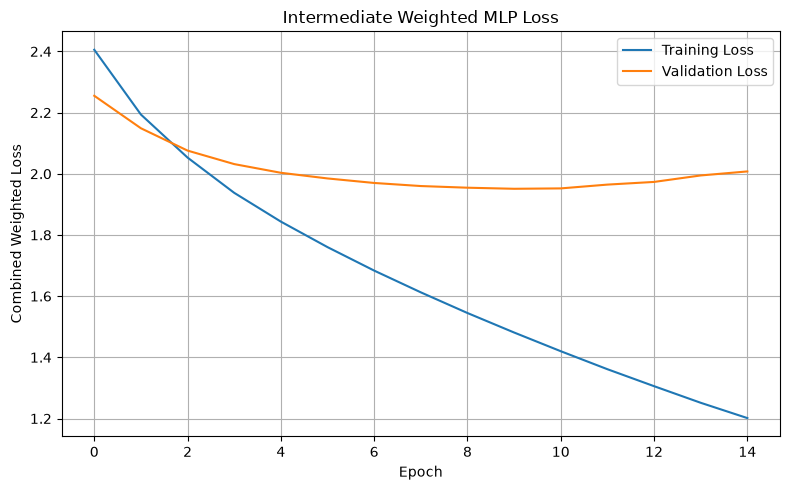

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    intermediate_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    intermediate_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Combined Weighted Loss")
plt.title("Intermediate Weighted MLP Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [10]:

# Check available metric names
print(intermediate_history.history.keys())

dict_keys(['complications_loss', 'complications_precision', 'complications_recall', 'let_is_accuracy', 'let_is_loss', 'loss', 'val_complications_loss', 'val_complications_precision', 'val_complications_recall', 'val_let_is_accuracy', 'val_let_is_loss', 'val_loss'])


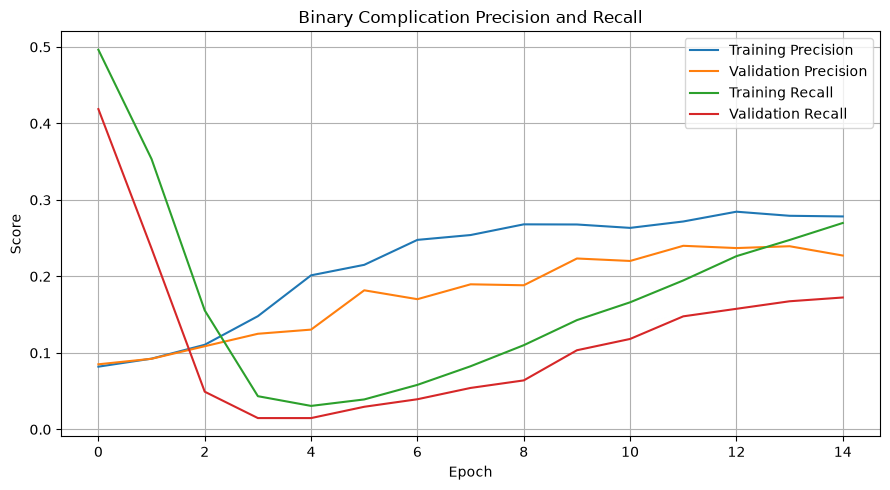

In [11]:
history = intermediate_history.history

plt.figure(figsize=(9, 5))

plt.plot(
    history["complications_precision"],
    label="Training Precision"
)

plt.plot(
    history["val_complications_precision"],
    label="Validation Precision"
)

plt.plot(
    history["complications_recall"],
    label="Training Recall"
)

plt.plot(
    history["val_complications_recall"],
    label="Validation Recall"
)

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Binary Complication Precision and Recall")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


9. Verifying the model makes predictions

In [12]:
# Predict 5 patients
binary_probs, let_probs = (
    intermediate_model.predict(X_val_np[:5])
)

binary_preds = (
    binary_probs >= 0.5
).astype(int)

let_preds = np.argmax(let_probs, axis=1)

print("Binary complication predictions:")
print(binary_preds)

print("\nLET_IS predictions:")
print(let_preds)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Binary complication predictions:
[[0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 1 0 0]
 [0 0 0 0 0 0 0 0 1 0 0]
 [0 0 0 0 0 0 0 0 0 0 0]]

LET_IS predictions:
[0 0 0 0 0]


10. Checking predictions across the entire validation set

In [13]:
binary_probs, let_probs = (
    intermediate_model.predict(X_val_np)
)

binary_preds = (
    binary_probs >= 0.5
).astype(int)

let_preds = np.argmax(let_probs, axis=1)

print("Positive predictions per complication:")

for i, col in enumerate(binary_cols):
    print(f"{col}: {binary_preds[:, i].sum()}")

print("\nLET_IS predicted class distribution:")
print(pd.Series(let_preds).value_counts().sort_index())


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Positive predictions per complication:
FIBR_PREDS: 13
PREDS_TAH: 0
JELUD_TAH: 7
FIBR_JELUD: 10
A_V_BLOK: 3
OTEK_LANC: 5
RAZRIV: 7
DRESSLER: 5
ZSN: 34
REC_IM: 6
P_IM_STEN: 4

LET_IS predicted class distribution:
0    214
1     15
3     16
4      5
5      1
6      1
7      3
Name: count, dtype: int64


11. Checking actual vs predicted complications

In [14]:
# Generate predictions using the intermediate weighted model
intermediate_binary_probs, intermediate_let_probs = intermediate_model.predict(X_val_np)

# Convert probabilities to predictions
intermediate_binary_preds = (intermediate_binary_probs >= 0.5).astype(int)
intermediate_let_preds = np.argmax(intermediate_let_probs, axis=1)

# Compare actual vs predicted positive cases for each complication
intermediate_comparison = pd.DataFrame({
    "Complication": binary_cols,
    "Actual Positives": y_val_binary.sum(axis=0).astype(int),
    "Predicted Positives": intermediate_binary_preds.sum(axis=0)
})

display(intermediate_comparison)

# Compare actual vs predicted LET_IS class distributions
print("\nActual LET_IS distribution:")
print(
    pd.Series(y_val_let)
    .value_counts()
    .reindex(range(8), fill_value=0)
)

print("\nPredicted LET_IS distribution:")
print(
    pd.Series(intermediate_let_preds)
    .value_counts()
    .reindex(range(8), fill_value=0)
)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Complication,Actual Positives,Predicted Positives
0,FIBR_PREDS,26,13
1,PREDS_TAH,3,0
2,JELUD_TAH,7,7
3,FIBR_JELUD,11,10
4,A_V_BLOK,8,3
5,OTEK_LANC,24,5
6,RAZRIV,8,7
7,DRESSLER,11,5
8,ZSN,59,34
9,REC_IM,24,6



Actual LET_IS distribution:
0    215
1     16
2      3
3      8
4      3
5      2
6      4
7      4
Name: count, dtype: int64

Predicted LET_IS distribution:
0    214
1     15
2      0
3     16
4      5
5      1
6      1
7      3
Name: count, dtype: int64


12. Checking false positives and false negatives

In [15]:
from sklearn.metrics import confusion_matrix

results = []

for i, col in enumerate(binary_cols):
    tn, fp, fn, tp = confusion_matrix(
        y_val_binary[:, i],
        binary_preds[:, i],
        labels=[0, 1]
    ).ravel()

    results.append({
        "Complication": col,
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn,
        "True Negatives": tn
    })

confusion_df = pd.DataFrame(results)

display(confusion_df)


,Complication,True Positives,False Positives,False Negatives,True Negatives
0,FIBR_PREDS,3,10,23,219
1,PREDS_TAH,0,0,3,252
2,JELUD_TAH,0,7,7,241
3,FIBR_JELUD,0,10,11,234
4,A_V_BLOK,1,2,7,245
5,OTEK_LANC,1,4,23,227
6,RAZRIV,0,7,8,240
7,DRESSLER,0,5,11,239
8,ZSN,13,21,46,175
9,REC_IM,3,3,21,228


Summary

In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Generate predictions using the intermediate weighted model
intermediate_binary_probs, intermediate_let_probs = intermediate_model.predict(X_val_np)

# Convert probabilities to binary predictions
intermediate_binary_preds = (intermediate_binary_probs >= 0.5).astype(int)

# Calculate metrics for each complication
intermediate_metrics_summary = pd.DataFrame({
    "Complication": binary_cols,
    "Accuracy": [
        accuracy_score(y_val_binary[:, i], intermediate_binary_preds[:, i])
        for i in range(len(binary_cols))
    ],
    "Macro Precision": [
        precision_score(y_val_binary[:, i], intermediate_binary_preds[:, i],
                        average="macro", zero_division=0)
        for i in range(len(binary_cols))
    ],
    "Macro Recall": [
        recall_score(y_val_binary[:, i], intermediate_binary_preds[:, i],
                     average="macro", zero_division=0)
        for i in range(len(binary_cols))
    ],
    "Macro F1": [
        f1_score(y_val_binary[:, i], intermediate_binary_preds[:, i],
                 average="macro", zero_division=0)
        for i in range(len(binary_cols))
    ]
})
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Get predicted LET_IS classes from the intermediate weighted model
intermediate_let_preds = np.argmax(intermediate_let_probs, axis=1)

# Calculate LET_IS metrics
intermediate_let_metrics_summary = pd.DataFrame({
    "Target": ["LET_IS"],
    "Accuracy": [
        accuracy_score(y_val_let, intermediate_let_preds)
    ],
    "Macro Precision": [
        precision_score(
            y_val_let, intermediate_let_preds,
            labels=np.arange(8),
            average="macro",
            zero_division=0
        )
    ],
    "Macro Recall": [
        recall_score(
            y_val_let, intermediate_let_preds,
            labels=np.arange(8),
            average="macro",
            zero_division=0
        )
    ],
    "Macro F1": [
        f1_score(
            y_val_let, intermediate_let_preds,
            labels=np.arange(8),
            average="macro",
            zero_division=0
        )
    ]
})

# Combine binary complications and LET_IS into one table
all_metrics_summary = pd.concat(
    [intermediate_metrics_summary, intermediate_let_metrics_summary],
    ignore_index=True
)

# Display results
display(all_metrics_summary.round(4))

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


,Complication,Accuracy,Macro Precision,Macro Recall,Macro F1,Target
0,FIBR_PREDS,0.8706,0.5679,0.5359,0.5419,NaN
1,PREDS_TAH,0.9882,0.4941,0.5000,0.4970,NaN
2,JELUD_TAH,0.9451,0.4859,0.4859,0.4859,NaN
3,FIBR_JELUD,0.9176,0.4776,0.4795,0.4785,NaN
4,A_V_BLOK,0.9647,0.6528,0.5585,0.5819,NaN
5,OTEK_LANC,0.8941,0.5540,0.5122,0.5064,NaN
6,RAZRIV,0.9412,0.4839,0.4858,0.4848,NaN
7,DRESSLER,0.9373,0.4780,0.4898,0.4838,NaN
8,ZSN,0.7373,0.5871,0.5566,0.5594,NaN
9,REC_IM,0.9059,0.7078,0.5560,0.5750,NaN
